# 🛠️ SWE-Agent: Applied Tool Use for Autonomous Bug Fixing

## Learning Objectives
In this notebook, you will learn:
1. **What a SWE-Agent is** - A ReAct agent whose tools are the developer workflow: read, edit, run tests
2. **A safe sandbox** - Building a throwaway project so the agent can never touch real files
3. **A constrained tool surface** - File and test tools that cannot escape the sandbox or run arbitrary commands
4. **The ReAct loop with a turn budget** - The same `agent ⇄ tools` graph, bounded by `MAX_TURNS`
5. **Verifying the agent's work** - Diffing its edits and re-running the tests outside the loop

## Where this fits
This notebook is an **applied build** of the Tool Use / ReAct pattern from `01_react_agent_langgraph.ipynb` and `02_tool_calling_vs_react.ipynb`. It does not introduce a new architecture -- it takes the same `think -> act -> observe` loop and applies it to a concrete, high-value domain: an autonomous **software-engineering agent** (SWE-Agent-style) that reads buggy source code, edits it, reruns a test suite, and iterates until the tests pass. `06_browser_agent_computer_use.ipynb` applies the same loop to a browser.

The idea is inspired by the `33_swe_agent` concept in FareedKhan-dev's `all-agentic-architectures` repository (not downloaded here -- we replicate the concept from scratch with our own tiny, self-contained project).

## Prerequisites
- The ReAct loop in LangGraph — `01_react_agent_langgraph.ipynb`
- Dependencies installed with `uv sync` at the repository root (includes `pytest`, which the agent's test tool runs)
- `OPENAI_API_KEY` in the project-root `.env`. No other keys are needed.

| Property | Value |
|---|---|
| Origin | Yang et al., *SWE-agent: Agent-Computer Interfaces Enable Automated Software Engineering* (Princeton 2024). [arXiv:2405.15793](https://arxiv.org/abs/2405.15793) |

---
## 📦 Step 1: Environment Setup

Load the API key and the libraries we need (`tempfile`, `subprocess`, `pathlib`, LangGraph, LangChain tool decorators), then create the LLM.

In [1]:
# ============================================================================
# ENVIRONMENT SETUP: Imports, API keys and a console for readable output
# ============================================================================
import difflib
import subprocess
import tempfile
import warnings
from pathlib import Path
from typing import Annotated, TypedDict

from dotenv import find_dotenv, load_dotenv
from langchain_core.messages import AnyMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from rich.console import Console
from rich.syntax import Syntax

warnings.filterwarnings("ignore")

# Reads OPENAI_API_KEY from the project-root .env
load_dotenv(find_dotenv(usecwd=True))

console = Console()
print("✅ Environment ready")

✅ Environment ready


In [2]:
# ============================================================================
# LLM INITIALIZATION: The agent's reasoning engine
# ============================================================================
from aied_helpers import get_openai_llm

llm = get_openai_llm(model="gpt-4o-mini")

print(f"✅ LLM initialized: {llm.model_name}")

✅ LLM initialized: gpt-4o-mini


---
## 🧑‍💻 Part 1: What a SWE-Agent Is

### Definition
A **SWE-Agent** is a ReAct-style agent whose tool set is the standard developer workflow: inspect files, edit files, and run tests. The "reasoning loop" is the same as any ReAct agent -- think, act, observe, repeat -- but the actions are code edits and the observations are test results (pass/fail + stack traces).

### High-level Workflow
1. **Read:** The agent lists and reads the project's source files to understand what exists.
2. **Test:** The agent runs the test suite to see which tests currently fail and why (the failure message *is* the bug report).
3. **Think:** The agent reasons about the root cause of the failure from the file contents and the error output.
4. **Act:** The agent calls `write_file(path, content)` to apply a fix.
5. **Observe:** The agent reruns `run_tests()` to check whether the fix worked.
6. **Repeat:** Steps 3-5 loop until all tests pass or a maximum turn budget is exhausted.

### When to Use / Applications
* **Automated bug triage:** Given a failing CI test, have an agent localize and patch the defect.
* **Repetitive maintenance fixes:** Off-by-one errors, wrong operators, incorrect string handling -- the kind of bug a junior engineer fixes quickly given a failing test as a spec.
* **Any tool-use scenario where test execution serves as a ground-truth reward signal**, letting the agent self-verify instead of relying purely on its own judgment.

### Strengths & Weaknesses
* **Strengths:**
    * **Self-verifying:** The agent doesn't have to *believe* its fix is correct -- `run_tests()` tells it objectively.
    * **Naturally bounded:** The test suite acts as a stopping criterion, avoiding endless "am I done?" ambiguity.
    * **Directly reuses the ReAct loop:** No new agent architecture is required, only domain-specific tools.
* **Weaknesses:**
    * **Only as good as the tests:** A test suite with poor coverage lets the agent "fix" the visible symptom while leaving other bugs untouched, or even overfit a patch to the exact assertions.
    * **Unsafe without sandboxing:** An agent with `write_file` + `run_tests` (arbitrary code execution) tools is dangerous if pointed at a real codebase or given a real shell.
    * **Turn-budget risk:** Like any ReAct loop, a poorly guided agent can thrash between incorrect fixes without converging.

### ⚠️ Safety Note

**All file operations in this notebook are confined to a throwaway directory created with `tempfile.mkdtemp()`.** The agent never sees, reads, or writes any path in this repository. The scratch directory contains only files that this notebook itself generates in Phase 1 below, and it is safe to delete (or simply let the OS reclaim it) once the notebook finishes. `run_tests()` only ever invokes `pytest` inside that scratch directory -- it never runs arbitrary shell commands supplied by the model.

---
## 🏗️ Part 2: Building the Scratch Project (Safe Sandbox)

We create a brand-new temporary directory with `tempfile.mkdtemp()` and write two small, deliberately-buggy Python modules plus a `pytest` test suite into it -- all authored inline by this notebook, so nothing pre-existing is touched. This scratch directory is the *entire* world the agent is allowed to operate in.

In [3]:
# ============================================================================
# SCRATCH PROJECT SETUP: two buggy modules and a pytest suite in a temp dir
# ============================================================================
SCRATCH_DIR = Path(tempfile.mkdtemp(prefix="swe_agent_scratch_"))
console.print(f"[bold cyan]Scratch sandbox created at:[/bold cyan] {SCRATCH_DIR}")

# --- Buggy module 1: math_utils.py -----------------------------------------
math_utils_buggy = '''"""Small math helper functions."""


def add(a, b):
    return a + b


def subtract(a, b):
    return a + b


def average(numbers):
    return sum(numbers) / len(numbers)
'''

# --- Buggy module 2: string_utils.py ---------------------------------------
string_utils_buggy = '''"""Small string helper functions."""


def reverse_string(s):
    return s


def is_palindrome(s):
    cleaned = s.lower().replace(" ", "")
    return cleaned == reverse_string(cleaned)
'''

# --- Test suite --------------------------------------------------------
test_suite = '''"""Pytest suite the SWE-Agent must make pass."""
from math_utils import add, average, subtract
from string_utils import is_palindrome, reverse_string


def test_add():
    assert add(2, 3) == 5


def test_subtract():
    assert subtract(10, 4) == 6


def test_average():
    assert average([2, 4, 6]) == 4


def test_reverse_string():
    assert reverse_string("hello") == "olleh"


def test_is_palindrome_true():
    assert is_palindrome("racecar") is True


def test_is_palindrome_false():
    assert is_palindrome("python") is False
'''

(SCRATCH_DIR / "math_utils.py").write_text(math_utils_buggy, encoding="utf-8")
(SCRATCH_DIR / "string_utils.py").write_text(string_utils_buggy, encoding="utf-8")
(SCRATCH_DIR / "test_suite.py").write_text(test_suite, encoding="utf-8")

console.print("[green]Scratch project written:[/green]", [p.name for p in SCRATCH_DIR.iterdir()])

Scratch sandbox created at: /var/folders/16/l0pt1ckj4hg1jzr4894_3f340000gn/T/swe_agent_scratch_60c0uv2p

Scratch project written:
['math_utils.py', 'string_utils.py', 'test_suite.py']

The sandbox now contains two source files with real bugs (`subtract` adds instead of subtracting; `reverse_string` doesn't reverse anything, which also breaks `is_palindrome`) and a `pytest` suite that will fail on exactly those two bugs. Note that `test_add` and `test_average` should already pass -- the agent needs to find and fix *only* what's broken, not rewrite everything.

The bugs are described here for you, the reader. The source files the agent reads carry no `# BUG` hints — the failing tests are its only bug report, as in a real repository.

---
## 🔧 Part 3: Defining the Agent's Tools

We give the agent the four tools a developer actually uses: `list_files`, `read_file`, `write_file`, and `run_tests`. Every tool resolves paths against `SCRATCH_DIR` only -- even if the model hallucinates an absolute path elsewhere, `Path(...).name` strips it back down to a filename inside the sandbox, so the agent structurally cannot escape the scratch directory.

In [4]:
# ============================================================================
# AGENT TOOLS: list, read, write and test — all confined to SCRATCH_DIR
# ============================================================================
import sys


def _safe_path(filename: str) -> Path:
    """Resolve a filename to a path strictly inside SCRATCH_DIR."""
    return SCRATCH_DIR / Path(filename).name


@tool
def list_files() -> str:
    """List every file currently in the scratch project directory."""
    return "\n".join(sorted(p.name for p in SCRATCH_DIR.iterdir() if p.is_file()))


@tool
def read_file(path: str) -> str:
    """Read and return the full contents of a file in the scratch project.

    Args:
        path: The filename to read, e.g. 'math_utils.py'.
    """
    target = _safe_path(path)
    if not target.exists():
        return f"ERROR: {target.name} does not exist in the scratch project."
    return target.read_text(encoding="utf-8")


@tool
def write_file(path: str, content: str) -> str:
    """Overwrite a file in the scratch project with new content (the fix).

    Args:
        path: The filename to write, e.g. 'math_utils.py'.
        content: The complete new source code for that file.
    """
    target = _safe_path(path)
    target.write_text(content, encoding="utf-8")
    return f"Wrote {len(content)} characters to {target.name}."


@tool
def run_tests() -> str:
    """Run the pytest suite in the scratch project and return pass/fail + output."""
    # sys.executable -m pytest: the kernel's own interpreter, not whatever `pytest` is on PATH
    result = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "test_suite.py"],
        cwd=str(SCRATCH_DIR),
        capture_output=True,
        text=True,
        timeout=30,
    )
    status = "PASSED" if result.returncode == 0 else "FAILED"
    return f"STATUS: {status}\n\n{result.stdout}\n{result.stderr}"


tools = [list_files, read_file, write_file, run_tests]
llm_with_tools = llm.bind_tools(tools)

console.print("[green]Registered tools:[/green]", [t.name for t in tools])

Registered tools:
['list_files', 'read_file', 'write_file', 'run_tests']

`run_tests()` shells out to `pytest` with a working directory pinned to `SCRATCH_DIR` -- it never receives an arbitrary command from the model, only a fixed, hard-coded invocation. This is the same "constrained tool surface" principle used by production coding agents: the LLM chooses *when* to run tests, not *what* command runs.

---
## 🔁 Part 4: The ReAct Loop as a LangGraph

We wire the agent into the familiar ReAct graph: an `agent` node that thinks and (optionally) calls a tool, a `tools` node that executes it, and an edge from `tools` back to `agent` so the loop continues. We add one addition on top of the plain ReAct pattern from `01_react_agent_langgraph.ipynb`: a `turn_count` field in the state so we can enforce a hard cap on iterations, since a coding agent that keeps guessing wrong fixes could otherwise loop indefinitely.

In [5]:
# ============================================================================
# REACT GRAPH (SWE-AGENT LOOP): agent ⇄ tools with a turn budget
# ============================================================================
# Each turn is one model call; a clean run needs ~5 (inspect, test, fix, re-test, report),
# so 10 bounds a thrashing agent without deciding a normal run's outcome.
MAX_TURNS = 10


class SWEAgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    turn_count: int


SYSTEM_PROMPT = """You are an autonomous software-engineering agent (SWE-Agent).
You are working inside a small Python project. Your goal is to make ALL tests in
test_suite.py pass, changing as little as possible.

Follow this loop:
1. Use list_files and read_file to inspect the project.
2. Use run_tests to see which tests fail and why.
3. Reason about the root cause from the failing assertion / traceback.
4. Use write_file to apply a minimal, targeted fix to the buggy file.
5. Use run_tests again to confirm the fix worked.

Only stop calling tools once run_tests reports STATUS: PASSED. Do not rewrite
files that are not implicated by a failing test."""


def agent_node(state: SWEAgentState):
    console.print(f"--- SWE-AGENT: Thinking (turn {state['turn_count'] + 1}/{MAX_TURNS})... ---")
    messages = [("system", SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response], "turn_count": state["turn_count"] + 1}


def router(state: SWEAgentState):
    last_message = state["messages"][-1]
    if state["turn_count"] >= MAX_TURNS:
        console.print("--- ROUTER: Max turn budget reached. Stopping. ---")
        return "__end__"
    if getattr(last_message, "tool_calls", None):
        console.print("--- ROUTER: Decision is to call a tool. ---")
        return "tools"
    console.print("--- ROUTER: Decision is to finish. ---")
    return "__end__"


swe_graph_builder = StateGraph(SWEAgentState)
swe_graph_builder.add_node("agent", agent_node)
swe_graph_builder.add_node("tools", ToolNode(tools))

swe_graph_builder.set_entry_point("agent")
swe_graph_builder.add_conditional_edges("agent", router, {"tools": "tools", "__end__": "__end__"})
swe_graph_builder.add_edge("tools", "agent")

swe_agent_app = swe_graph_builder.compile()
console.print("[bold green]SWE-Agent graph compiled successfully.[/bold green]")

SWE-Agent graph compiled successfully.

Structurally this is identical to the ReAct graph in `01_react_agent_langgraph.ipynb` -- an `agent` <-> `tools` loop -- with the only domain-specific additions being the tool set (file/test operations instead of web search) and the `turn_count` safety valve in the router. This is exactly the point of an "applied" notebook: the underlying primitive doesn't change, only its instantiation.

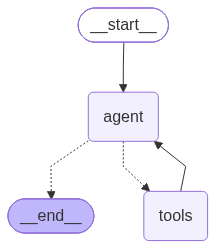

In [6]:
swe_agent_app

---
## ▶️ Part 5: Running the Agent and Verifying Its Work

We snapshot the buggy files before the run, invoke the agent with the task instruction, stream every intermediate state so we can narrate each think/act/observe step, and finally diff the "before" and "after" contents of every file the agent touched.

In [7]:
# ============================================================================
# RUN THE AGENT: snapshot the files, then stream every turn
# ============================================================================
before_snapshot = {
    p.name: p.read_text(encoding="utf-8")
    for p in SCRATCH_DIR.iterdir()
    if p.suffix == ".py" and p.name != "test_suite.py"
}

task_instruction = (
    "The project's test suite (test_suite.py) is failing. "
    "Investigate, fix the bugs, and make all tests pass."
)

console.print(f"[bold yellow]Task given to SWE-Agent:[/bold yellow] {task_instruction}\n")

final_state = None
for chunk in swe_agent_app.stream(
    {"messages": [("user", task_instruction)], "turn_count": 0},
    stream_mode="values",
):
    final_state = chunk
    last_msg = chunk["messages"][-1]
    console.print("--- [bold purple]Agent turn[/bold purple] ---")
    last_msg.pretty_print()
    console.print()

Task given to SWE-Agent: The project's test suite (test_suite.py) is failing. Investigate, fix the bugs, and make 
all tests pass.

--- Agent turn ---

================================ Human Message =================================

The project's test suite (test_suite.py) is failing. Investigate, fix the bugs, and make all tests pass.


--- SWE-AGENT: Thinking (turn 1/10)... ---

--- ROUTER: Decision is to call a tool. ---

...

================================= Tool Message =================================
Name: run_tests

STATUS: PASSED

......                                                                   [100%]
6 passed in 0.00s




--- SWE-AGENT: Thinking (turn 8/10)... ---

--- ROUTER: Decision is to finish. ---

--- Agent turn ---

================================== Ai Message ==================================

All tests in the test suite have passed successfully. Here’s a summary of the changes made:

1. **math_utils.py**:
   - Fixed the `subtract` function to correctly perform subtraction (`return a - b`).
   - Added a check in the `average` function to handle empty lists.

2. **string_utils.py**:
   - Updated the `reverse_string` function to correctly reverse the input string (`return s[::-1]`).

With these changes, all tests are now passing.


Reading the streamed trace top to bottom shows the ReAct loop in action end-to-end:
1. **Think:** The agent calls `list_files` / `read_file` to orient itself in the unfamiliar project.
2. **Act (Observe the bug):** It calls `run_tests`, and the pytest output -- assertion failures for `test_subtract` and `test_reverse_string` (which also cascades into `test_is_palindrome_true`) -- becomes its bug report.
3. **Think:** It reasons from the `AssertionError` messages and the buggy source (`subtract` returning `a + b`; `reverse_string` returning `s` unchanged) to a minimal fix.
4. **Act (fix):** It calls `write_file` with corrected source for `math_utils.py` and/or `string_utils.py`.
5. **Observe:** It calls `run_tests` again; once the output shows `STATUS: PASSED`, the router routes to `__end__` instead of back to `tools`.

If the model needed more than one attempt, you would see the loop repeat with a different patch each time, bounded by `MAX_TURNS`.

In [8]:
# ============================================================================
# BEFORE / AFTER DIFF: exactly what the agent changed
# ============================================================================
after_snapshot = {
    p.name: p.read_text(encoding="utf-8")
    for p in SCRATCH_DIR.iterdir()
    if p.suffix == ".py" and p.name != "test_suite.py"
}

for filename, before_text in before_snapshot.items():
    after_text = after_snapshot[filename]
    if before_text == after_text:
        continue
    console.print(f"\n[bold cyan]--- Diff for {filename} ---[/bold cyan]")
    diff = difflib.unified_diff(
        before_text.splitlines(keepends=True),
        after_text.splitlines(keepends=True),
        fromfile=f"before/{filename}",
        tofile=f"after/{filename}",
    )
    console.print(Syntax("".join(diff), "diff", theme="ansi_dark"))

last_message = final_state["messages"][-1]
console.print("\n[bold green]--- Final agent message ---[/bold green]")
console.print(last_message.content)

--- Diff for math_utils.py ---

--- before/math_utils.py
+++ after/math_utils.py
@@ -1,13 +1,12 @@
 """Small math helper functions."""
-
 
 def add(a, b):
     return a + b
 
 
 def subtract(a, b):
-    return a + b
+    return a - b
 
 
 def average(numbers):
-    return sum(numbers) / len(numbers)
+    return sum(numbers) / len(numbers) if numbers else 0

--- Diff for string_utils.py ---

--- before/string_utils.py
+++ after/string_utils.py
@@ -1,8 +1,7 @@
 """Small string helper functions."""
 
-
 def reverse_string(s):
-    return s
+    return s[::-1]
 
 
 def is_palindrome(s):

--- Final agent message ---

All tests in the test suite have passed successfully. Here’s a summary of the changes made:

1. **math_utils.py**:
   - Fixed the `subtract` function to correctly perform subtraction (`return a - b`).
   - Added a check in the `average` function to handle empty lists.

2. **string_utils.py**:
   - Updated the `reverse_string` function to correctly reverse the input string (`return s[::-1]`).

With these changes, all tests are now passing.

The unified diff makes the agent's edit auditable at a glance -- exactly the two buggy lines (`subtract`'s `a + b` and `reverse_string`'s pass-through `return s`) should be the only lines that changed, confirming the agent applied a **minimal, targeted** fix rather than rewriting the files wholesale. This diff-based review is itself a useful pattern for any tool-use agent that edits files: always inspect what actually changed, not just whether the agent claims success.

Check whether that held in your run. A common deviation with `gpt-4o-mini` is an extra edit, such as `is_palindrome` rewritten to stop calling `reverse_string`: the tests still pass, but the agent changed code no failing test implicated — exactly what its system prompt told it not to do. Only the diff reveals that; the green test run does not.

In [9]:
# ============================================================================
# INDEPENDENT VERIFICATION: run the tests outside the agent loop
# ============================================================================
verification = run_tests.invoke({})
console.print("\n[bold]Final test run (verification outside the agent loop):[/bold]")
console.print(verification)

Final test run (verification outside the agent loop):

STATUS: PASSED

......                                                                   [100%]
6 passed in 0.00s

Running `run_tests()` one more time, independently of the agent's own tool calls, is a sanity check that the agent didn't just *claim* success in its final message -- the sandbox's test suite is the objective source of truth, and `STATUS: PASSED` here is the real proof the bugs are fixed.

---
## 📝 Summary

In this notebook, we learned:

### 1. What a SWE-Agent Is
- A ReAct agent whose actions are code edits and whose observations are test results
- **No new architecture was introduced.** The graph is the same `agent <-> tools` loop from `01_react_agent_langgraph.ipynb`; only the tool set and the domain changed

### 2. A Safe Sandbox
- Every file the agent sees lives in a `tempfile.mkdtemp()` directory this notebook created

### 3. A Constrained Tool Surface
- Paths are reduced to a filename inside the sandbox; `run_tests()` only ever runs a fixed `pytest` invocation — the agent cannot touch this repository or execute arbitrary shell commands, no matter what the model outputs

### 4. The ReAct Loop with a Turn Budget
- **Tests as a reward signal:** `run_tests()` turns "is this fixed?" into an objective, checkable question
- **Turn budgets matter:** `MAX_TURNS` stops an agent that keeps guessing wrong fixes; size it above what a clean run needs

### 5. Verifying the Agent's Work
- Diff what actually changed, and re-run the tests yourself — never trust the agent's final message alone

### Next Steps
- **`06_browser_agent_computer_use.ipynb`**: the identical Tool Use / ReAct primitive applied to a browser environment instead of a codebase